
# Math & Python Foundations for Machine Learning in Astronomy

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Danselem/brics_astro/blob/main/ml/00_Math_and_Python_Foundations.ipynb)

**Course:** Machine Learning in Astronomy — Pre-Course Notebook
**Audience:** MSc/PhD students in Astronomy, Space Science, Solar Physics, Cosmology

## Why this notebook exists

Every machine learning method you'll see in this course — from a simple linear fit to a deep neural network classifying galaxy images — is built out of the same small set of mathematical ideas: **derivatives**, **gradients**, **vectors**, **probability**, and **likelihood**. If these ideas feel odd to you now, later notebooks will feel like magic tricks instead of tools you understand and can debug. So this notebook goes slowly, uses astronomy examples throughout, and asks you to *change things when necessary and watch what happens* — that's where real intuition comes from, not from reading a formula once.

## How to use this notebook (please actually do this)

- Read the explanation **before** each code cell — it tells you what the code is about to do and why it matters.
- Run the cell, look at the plot, and read the interpretation.
- Then do the **"🔧 Try it yourself"** exercise that follows — change a number, re-run, and watch what changes. 
- If a plot confuses you, that's useful information, not a failure — it usually means one parameter needs to be nudged so you can see the effect it has. Nudge it.

## Learning objectives

By the end of this notebook you should be able to:
- Explain, in plain language, what a derivative and a gradient are, and why ML training follows the gradient downhill
- Implement gradient descent from scratch and describe what happens when the learning rate is too big or too small
- Explain what a vector, a covariance matrix, and an eigenvector represent geometrically for astronomical measurements
- Explain the Poisson and Gaussian distributions and why one becomes the other at high photon counts
- Explain Bayes' theorem in your own words and describe what happens to a belief as more data arrives
- Explain Maximum Likelihood Estimation and how it connects to the loss-minimization idea from gradient descent
- Explain, with an example, what "overfitting" and "underfitting" mean

## Table of contents
1. Python & data handling refresher
2. Derivatives and the gradient vector
3. Gradient descent (animated)
4. Vectors, matrices, and eigenvectors
5. Probability distributions (animated)
6. Bayes' theorem (animated)
7. Maximum likelihood estimation
8. Bias–variance tradeoff
9. Self-check questions


In [19]:

# Core scientific stack
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401  (enables 3D projection)
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

# Statistics
from scipy.stats import norm, multivariate_normal

# Astronomy
from astropy.table import Table
from astropy.io import fits

# Reproducibility: using a fixed "seed" means everyone gets the same random
# numbers, so your plots will match the explanations in this notebook exactly.
np.random.seed(42)

%matplotlib inline
plt.rcParams['figure.dpi'] = 100
print("Environment ready.")


Environment ready.



## 1. Python & Data Handling Refresher

### Why this matters
Before we can do any machine learning, we need to be comfortable with how astronomical data is actually *stored and moved around*. In this course you'll constantly work with three containers:

- **`numpy` arrays** — the basic building block for numbers in Python. Every image, spectrum, and light curve eventually becomes a numpy array.
- **`pandas` / `astropy` tables** — a **catalog** is just a table: one row per object (a star, a galaxy), one column per measured quantity (magnitude, color, redshift). This is exactly what you get when you query SDSS, Gaia, or any survey database.
- **FITS files** — the standard file format for astronomical images and spectra (Flexible Image Transport System). If you've ever downloaded a telescope image, it was almost certainly a `.fits` file.

### Why numpy arrays instead of plain Python lists?
A Python list can hold anything and is flexible, but it's slow for numerical work and doesn't support the kind of "do this operation to every element at once" behavior we need. A numpy array is a fixed-type grid of numbers that lets you write `magnitudes - 18` and have it subtract 18 from *every* element instantly — this is called **vectorization**, and it's the reason numerical Python code runs fast enough for machine learning at all.

### What the code below will do
We'll create a tiny numpy array of magnitudes, do a vectorized operation on it, then build a small "catalog" (a table with an object ID, a magnitude, and a color) using both `pandas` and `astropy.table.Table` — you'll see they hold the same information, just with different astronomy-specific conveniences in the `astropy` version (like the ability to attach physical units).


In [2]:
# --- numpy: the array is the basic unit of almost everything in ML ---
magnitudes = np.array([18.2, 17.9, 19.4, 18.0, 20.1])
colors     = np.array([0.5, 0.3, 0.8, 0.4, 1.1])

print("Mean magnitude:", magnitudes.mean())
print("Broadcasting example (mag - 18):", magnitudes - 18)

# --- pandas: tabular data with labeled columns, like a catalog ---
catalog = pd.DataFrame({
    "object_id": np.arange(1, 6),
    "g_mag": magnitudes,
    "g_minus_r": colors
})
catalog

Mean magnitude: 18.72
Broadcasting example (mag - 18): [ 0.2 -0.1  1.4  0.   2.1]


,object_id,g_mag,g_minus_r
0,1,18.2,0.5
1,2,17.9,0.3
2,3,19.4,0.8
3,4,18.0,0.4
4,5,20.1,1.1



**🔧 Try it yourself:** Change the numbers in `magnitudes` or `colors` (or add a 6th value to both arrays) and re-run the cell above. Notice that `magnitudes.mean()` and the subtraction both update automatically — you never had to write a loop. Now try `magnitudes * 2` or `magnitudes / colors` in a new cell: vectorized arithmetic works the same way for any operation.



### FITS files: reading and writing real telescope-style data

A FITS file typically stores a 2D (or 3D) array of pixel values plus a **header** — metadata like exposure time, telescope name, and coordinates. Below, we *simulate* a tiny star image (a bright blob following a 2D Gaussian shape, which is what a star's light looks like after passing through a telescope's optics — this is called the **point spread function**), add realistic background noise, and then write it to an actual `.fits` file and read it back — exactly the round-trip you'd do with real downloaded data.


object_id g_mag g_minus_r
--------- ----- ---------
        1  18.2       0.5
        2  17.9       0.3
        3  19.4       0.8
        4  18.0       0.4
        5  20.1       1.1


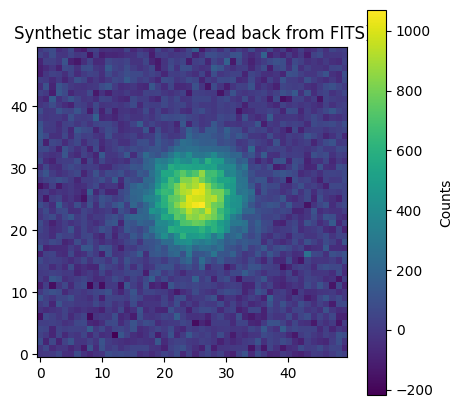

In [9]:
# --- astropy Table: astronomy's preferred tabular format (keeps units & metadata) ---
astropy_catalog = Table.from_pandas(catalog)
print(astropy_catalog)

# --- FITS files: the standard format for astronomical images and spectra ---
size = 50
y, x = np.mgrid[0:size, 0:size]
x0, y0, sigma, amplitude = 25, 25, 5.0, 1000
star_image = amplitude * np.exp(-(((x - x0)**2 + (y - y0)**2) / (2 * sigma**2)))
star_image += np.random.normal(0, 60, star_image.shape)  # background noise

hdu = fits.PrimaryHDU(star_image.astype(np.float32))
hdu.writeto('synthetic_star.fits', overwrite=True)

# Read it back, just like you would with a downloaded FITS image
with fits.open('synthetic_star.fits') as hdul:
    loaded_image = hdul[0].data

fig, ax = plt.subplots(figsize=(5, 5))
im = ax.imshow(loaded_image, cmap='viridis', origin='lower')
ax.set_title("Synthetic star image (read back from FITS)")
plt.colorbar(im, ax=ax, label="Counts")
plt.show()


**🔧 Try it yourself:** Change `sigma` to `1.5` (a sharper, more focused star) or `10` (a blurrier one) and re-run — this mimics different "seeing" conditions or a defocused telescope. Then change the noise level (`np.random.normal(0, 15, ...)`) to `0, 60` and see how much harder it becomes to tell where the star even is. This noise-vs-signal tension is exactly what makes real astronomical measurements — and later, ML models trained on them — hard.



## 2. Derivatives and the Gradient Vector

### The idea, in plain language
Imagine you're looking at a light curve — brightness plotted against time. At any single moment, the brightness is either going up, down, or momentarily flat. The **derivative** is just a precise number for "how fast, and in which direction, is it changing right now" — the slope of the line that just grazes the curve at that one point (the **tangent line**).

Formally:
$$f'(x) = \lim_{h \to 0} \frac{f(x+h) - f(x)}{h}$$

Don't worry about the "limit" notation if it's unfamiliar — in practice, we approximate this on a computer by using a very small (but not zero) value of $h$, which is exactly what the code below does. That's called a **numerical derivative**, and it's often good enough for building intuition (real ML libraries use a more exact technique called *automatic differentiation*, but the intuition is identical).

### Why should an astronomer training a machine learning model care about slopes?
Every ML model has a **loss function** — a single number that measures ``how wrong is the model right now.'' Training a model means adjusting its internal parameters to make that number smaller. The derivative of the loss with respect to a parameter tells you: *if I nudge this parameter up slightly, does the loss go up or down, and how fast?* That single piece of information is what lets the computer improve the model automatically, without a human manually guessing better parameter values. This is the single most important idea in this whole notebook — everything else builds on it.

### From one variable to several: partial derivatives and the gradient
A real model usually has more than one adjustable parameter — think of fitting a line $y = \theta_0 + \theta_1 x$: there are two knobs, $\theta_0$ and $\theta_1$. A **partial derivative** asks "how does the loss change if I nudge *just one* of these knobs, holding the other fixed?" — like standing on a hillside and asking "how steep is it if I only walk east-to-west?" versus "only north-to-south?"

Stacking all the partial derivatives into a single vector gives the **gradient**:
$$\nabla f(\theta_0, \theta_1) = \left(\frac{\partial f}{\partial \theta_0},\ \frac{\partial f}{\partial \theta_1}\right)$$

The gradient vector has a beautifully simple geometric meaning: **it points in the direction of steepest increase** of the function, at that point. If you want to *decrease* the loss as fast as possible, you should step in exactly the *opposite* direction of the gradient. That single sentence is the entire idea behind gradient descent (Section 3).

### What the first code cell will do
We'll plot a wiggly function $f(x)$ (standing in for something like a loss curve or a light curve), compute its derivative numerically at one point, and draw the tangent line there so you can literally see "slope" as a line touching the curve. The function represented mathematically as $\sin x + 0.1 x^{2}$.

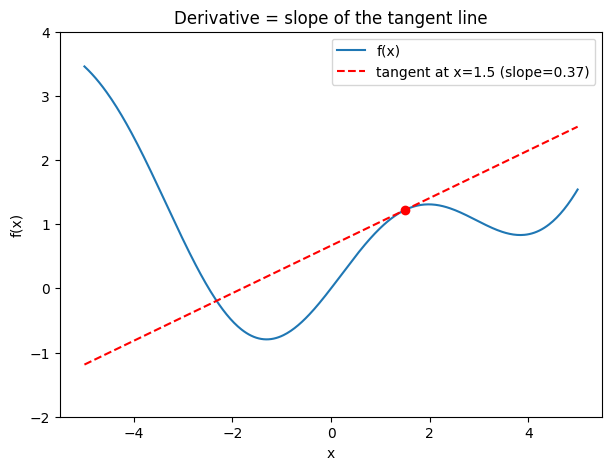

In [20]:

# 2D warm-up: derivative as the slope of a tangent line
def f(x):
    return np.sin(x) + 0.1 * x**2

def f_prime(x, h=1e-5):
    return (f(x + h) - f(x - h)) / (2 * h)

x = np.linspace(-5, 5, 400)
x0 = 1.5
slope = f_prime(x0)
tangent = f(x0) + slope * (x - x0)

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(x, f(x), label='f(x)')
ax.plot(x, tangent, '--', color='red', label=f'tangent at x={x0} (slope={slope:.2f})')
ax.scatter([x0], [f(x0)], color='red', zorder=5)
ax.set_xlabel('x'); ax.set_ylabel('f(x)')
ax.set_title('Derivative = slope of the tangent line')
ax.legend(); ax.set_ylim(-2, 4)
plt.show()



**🔧 Try it yourself:** Change `x0` to `-2.5` — notice the slope becomes negative, meaning the function is decreasing there. Now find a value of `x0` where the tangent line is almost perfectly flat (slope ≈ 0) — you've just found a local minimum or maximum by eye, which is exactly what gradient-based optimization finds automatically. Also try replacing `f(x)` with something simpler like `x**2` and see how the tangent line behaves at `x0 = 0`.



### What the next code cell will do
Now we extend the same "slope" idea to a function of *two* variables — imagine a loss surface shaped like a bowl, where the two horizontal axes are two model parameters ($\theta_0, \theta_1$) and height is the loss. We'll plot this bowl in 3D and draw the gradient vector as a red arrow at one point, so you can see it pointing "uphill," away from the bowl's minimum.


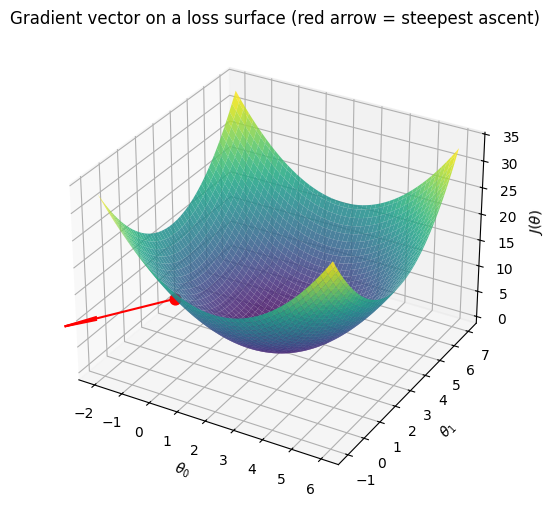

Gradient at (0,0): (-4.00, -6.00)  -> points toward the minimum at (2,3)


In [21]:

# 3D: the gradient vector on a loss surface J(theta0, theta1)
def loss(t0, t1):
    return (t0 - 2)**2 + (t1 - 3)**2 + 1

t0 = np.linspace(-2, 6, 100)
t1 = np.linspace(-1, 7, 100)
T0, T1 = np.meshgrid(t0, t1)
J = loss(T0, T1)

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(T0, T1, J, cmap='viridis', alpha=0.85)

point = (0.0, 0.0)
eps = 1e-4
g0 = (loss(point[0]+eps, point[1]) - loss(point[0]-eps, point[1])) / (2*eps)
g1 = (loss(point[0], point[1]+eps) - loss(point[0], point[1]-eps)) / (2*eps)
ax.scatter(*point, loss(*point), color='red', s=60)
ax.quiver(point[0], point[1], loss(*point), g0, g1, 0, length=0.5, color='red')
ax.set_xlabel(r'$\theta_0$'); ax.set_ylabel(r'$\theta_1$'); ax.set_zlabel(r'$J(\theta)$')
ax.set_title('Gradient vector on a loss surface (red arrow = steepest ascent)')
plt.show()

print(f"Gradient at (0,0): ({g0:.2f}, {g1:.2f})  -> points toward the minimum at (2,3)")



**🔧 Try it yourself:** Drag/rotate the 3D plot with your mouse to see the bowl shape from different angles. Then change `point = (0.0, 0.0)` to `point = (5.0, 6.0)` (on the other side of the minimum) and re-run — notice the arrow flips direction because "uphill" is now the opposite way. Try `point = (2.0, 3.0)` exactly at the minimum — what do you expect the gradient to be? Run it and check.



## 3. Gradient Descent — Fitting a Line to Real Data

### The idea, in plain language
Picture hiking down a mountain in thick fog. You can't see the bottom, but you can feel the slope of the ground right under your feet. A sensible strategy: take a small step in the steepest downhill direction, feel the new slope, take another small step, and repeat. Eventually you reach the bottom (or somewhere close to it). That's **gradient descent** — and the "mountain" is a loss function, the "bottom" is the set of parameters that make your model fit the data best.

Mathematiclly, at every step we update each parameter by moving a small amount opposite the gradient:
$$\theta_{t+1} = \theta_t - \eta \, \nabla_\theta J(\theta)$$

- $\theta_t$ — the current parameter values (your current position on the mountain)
- $\nabla_\theta J(\theta)$ — the gradient (which way is uphill, and how steep)
- $\eta$ (eta) — the **learning rate**: how big a step you take each time

**Why the learning rate matters so much:** too small, and you'll take forever to reach the bottom (training is painfully slow). Too large, and you might leap right over the valley and end up higher than where you started, potentially bouncing around forever without ever settling — this is called **divergence**. Picking a good learning rate is one of the most common practical challenges in real ML work, and you'll build intuition for it in the exercise below.

### The concrete problem we'll solve
We'll fit a straight line $\hat{y} = \theta_0 + \theta_1 x$ to a noisy data — imagine $x$ is a color index (like $g-r$) and $y$ is a magnitude, and there's a real underlying linear relationship buried in noisy measurements. We measure "wrongness" with the **mean squared error**:
$$J(\theta_0, \theta_1) = \frac{1}{m}\sum_{i=1}^m \left(\theta_0 + \theta_1 x^{(i)} - y^{(i)}\right)^2$$

This squares every prediction error (so positive and negative errors don't cancel out, and big errors are punished disproportionately more than small ones) and averages over all $m$ data points.

### What the code below will do
First we'll implement the update rule above from scratch (no ML library — just the formula), running it for 60 steps and recording the parameter values and loss at every step. Then we'll visualize the path those parameters took, both as a static picture and as an actual step-by-step animation, so you can watch the "hike down the mountain" happen.

In [22]:
# Synthetic color/magnitude data (swap in real SDSS ugriz columns later in the course)
np.random.seed(0)
x_data = np.random.uniform(0, 2, 50)                 # e.g. g-r color
y_data = 3*x_data + 2 + np.random.normal(0, 0.5, 50) # e.g. g magnitude

def compute_loss(t0, t1):
    return np.mean((t0 + t1*x_data - y_data)**2)

def gradient(t0, t1):
    err = t0 + t1*x_data - y_data
    return 2*np.mean(err), 2*np.mean(err*x_data)

theta0, theta1, lr, n_steps = -1.0, 0.0, 0.05, 60
path = [(theta0, theta1, compute_loss(theta0, theta1))]
for _ in range(n_steps):
    g0, g1 = gradient(theta0, theta1)
    theta0 -= lr * g0
    theta1 -= lr * g1
    path.append((theta0, theta1, compute_loss(theta0, theta1)))
path = np.array(path)

print(f"Final fit: y = {path[-1,0]:.2f} + {path[-1,1]:.2f} x   (true: y = 2.00 + 3.00 x)")

Final fit: y = 1.82 + 3.06 x   (true: y = 2.00 + 3.00 x)



**🔧 Try it yourself (important — this builds real intuition about the learning rate):**
- Set `lr = 0.5` and re-run. Watch the printed final fit — does it still recover `y = 2.00 + 3.00 x`? If not, you've just witnessed divergence.
- Set `lr = 0.001` and re-run with `n_steps = 60` — does 60 steps feel like enough anymore? Try `n_steps = 2000` to compensate.
- Reset `lr = 0.05` and try starting far away, e.g. `theta0, theta1 = -20.0, -20.0` — does it still find the right answer, and does it take longer?


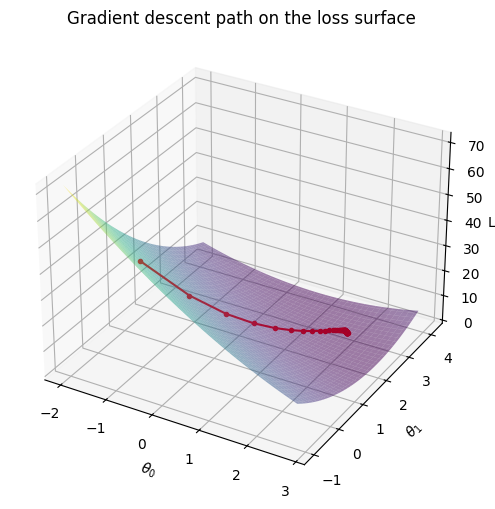

In [23]:
# Static 3D view: the loss surface + the descent path
t0_range = np.linspace(path[:, 0].min() - 1, path[:, 0].max() + 1, 80)
t1_range = np.linspace(path[:, 1].min() - 1, path[:, 1].max() + 1, 80)
T0, T1 = np.meshgrid(t0_range, t1_range)
J_grid = np.vectorize(compute_loss)(T0, T1)

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(T0, T1, J_grid, cmap='viridis', alpha=0.5)
ax.plot(path[:, 0], path[:, 1], path[:, 2], color='red', marker='o', markersize=3)
ax.set_xlabel(r'$\theta_0$'); ax.set_ylabel(r'$\theta_1$'); ax.set_zlabel('Loss')
ax.set_title('Gradient descent path on the loss surface')
plt.show()


Notice the red dots are packed close together near the start (small, cautious steps make sense there because the surface is unfamiliar) — actually, look closer: in this particular run the *opposite* often happens, with larger jumps early (steep slope, so a bigger raw gradient) and smaller jumps as it approaches the flat bottom (gradient shrinks near the minimum, since the slope flattens out). That naturally slowing-down behavior near the minimum is a useful thing to notice — it happens automatically, without us changing the learning rate.

### What the animation below adds
A static path is useful, but watching it unfold step by step makes the "hiking downhill" analogy concrete rather than abstract — you'll see exactly where progress is fast (steep region) and where it slows down (near the flat bottom).


In [24]:
# Animated version: watch gradient descent happen step by step
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(T0, T1, J_grid, cmap='viridis', alpha=0.4)
ax.set_xlabel(r'$\theta_0$'); ax.set_ylabel(r'$\theta_1$'); ax.set_zlabel('Loss')
title = ax.set_title('Gradient descent — step 0')

line, = ax.plot([], [], [], color='red', marker='o', markersize=3)

def init():
    line.set_data_3d([], [], [])
    return (line,)

def update(frame):
    line.set_data_3d(path[:frame+1, 0], path[:frame+1, 1], path[:frame+1, 2])
    title.set_text(f'Gradient descent — step {frame}')
    return (line,)

anim = FuncAnimation(fig, update, frames=len(path), init_func=init, interval=100, blit=False)
plt.close(fig)
HTML(anim.to_jshtml())


**🔧 Try it yourself:** Use the play controls under the animation to step through it frame by frame. Then go back up, change `lr` to something like `0.3` (borderline too large), re-run *all three* cells in this section in order, and watch the animation — you should see the red dot **zig-zag** back and forth across the valley instead of gliding smoothly to the bottom. That zig-zagging is a visual signature of a learning rate that's a bit too large.



## 4. Vectors, Matrices, and Eigenvectors

### The idea, in plain language
Suppose you measure a star in three photometric bands and get three magnitudes: 18.0, 17.5, 17.0. You can think of these three numbers as one point in a 3-dimensional space — or equivalently, as a **vector**. Every star in your catalog is a point in this space, and a whole catalog is a cloud of points.

Now here's the key question: real photometric bands aren't independent. A star that's unusually bright in one band tends to also be unusually bright in a neighboring band (they're all measuring the same underlying object, just at slightly different wavelengths). This tendency for measurements to move together is captured by the **covariance matrix** $\Sigma$ — a table of "how much does band $i$'s deviation from average predict band $j$'s deviation."

### Why should you care about the *shape* of this data cloud?
If bands are strongly correlated, the cloud of points isn't a neat sphere — it's stretched out, like a pancake, along certain directions. The directions along which the cloud is most stretched (most spread out) and least stretched are special: they're called **eigenvectors**, and the amount of spread along each is its **eigenvalue**:
$$\Sigma v_k = \lambda_k v_k$$

In plain language: $v_k$ is a direction that the covariance matrix doesn't rotate, only stretches — by a factor of $\lambda_k$. Finding these directions is *exactly* what **Principal Component Analysis (PCA)** does later in this course, when we compress a whole galaxy spectrum (hundreds of numbers) down to just a handful of "components" that capture most of the useful information. Understanding eigenvectors now means PCA won't feel like a black box later.

### What the code below will do
We'll generate 500 synthetic "stars," each with 3 correlated band magnitudes (using the covariance matrix we choose), plot them as a 3D scatter cloud, and draw the eigenvectors as red arrows scaled by their eigenvalues — so you can see the cloud's "natural axes" directly.


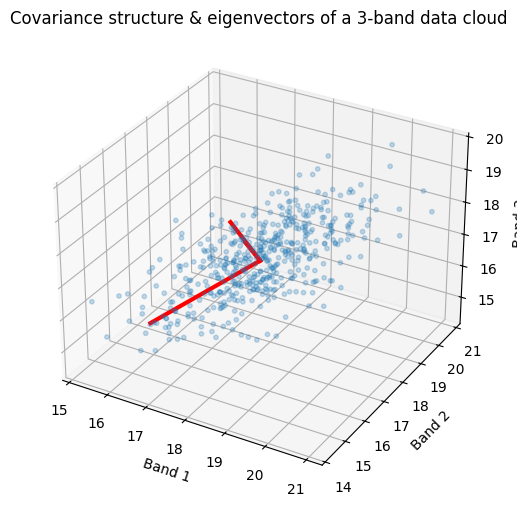

Eigenvalues (variance along each principal axis): [0.292 0.476 2.332]


In [25]:

# A synthetic 3-band ("ugr"-like) correlated data cloud
mean = [18.0, 17.5, 17.0]
cov = [[1.0, 0.8, 0.5],
       [0.8, 1.2, 0.6],
       [0.5, 0.6, 0.9]]
data = np.random.multivariate_normal(mean, cov, 500)
eigvals, eigvecs = np.linalg.eigh(cov)

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(data[:, 0], data[:, 1], data[:, 2], alpha=0.25, s=10)

origin = np.array(mean)
for val, vec in zip(eigvals, eigvecs.T):
    v = vec * np.sqrt(val) * 2
    ax.plot(*zip(origin, origin + v), color='red', linewidth=3)

ax.set_xlabel('Band 1'); ax.set_ylabel('Band 2'); ax.set_zlabel('Band 3')
ax.set_title('Covariance structure & eigenvectors of a 3-band data cloud')
plt.show()

print("Eigenvalues (variance along each principal axis):", np.round(eigvals, 3))


**🔧 Try it yourself:**
- Set every off-diagonal entry of `cov` to `0` (keep the diagonal as `[1.0, 1.2, 0.9]`) and re-run. The bands are now uncorrelated — what happens to the shape of the cloud and to the eigenvectors? (Expect them to line up with the plain x/y/z axes.)
- Now push the off-diagonal values close to their maximum allowed (try `0.95, 0.9, 0.85` roughly, keeping the matrix symmetric) and re-run — the cloud should become a thin, cigar-like shape stretched along one dominant eigenvector. Look at the printed eigenvalues: one should now be much larger than the other two.
- This second case is exactly what real spectra and images look like to PCA: highly correlated measurements that can be well-summarized by just one or two dominant directions.



## 5. Probability Distributions

### Why astronomers can't avoid probability
Telescopes count individual photons. Light is fundamentally quantized, so even if a source has a perfectly constant true brightness, the *number* of photons you happen to detect in a fixed time window will fluctuate randomly from one exposure to the next. This isn't a flaw in your instrument — it's physics. The **Poisson distribution** describes exactly this kind of counting process: if the true average rate is $\lambda$ (lambda), the probability of observing exactly $k$ photons is
$$P(k) = \frac{\lambda^k e^{-\lambda}}{k!}$$

A special, useful fact about the Poisson distribution: **its variance equals its mean** ($\lambda$). This is why, in photometry, the noise (uncertainty) on a photon count scales as $\sqrt{\lambda}$ — the well-known "shot noise" or "Poisson noise" you've likely encountered when computing error bars.

### Where the Gaussian (Normal) distribution comes from
When $\lambda$ is large (a bright source, lots of photons), the Poisson distribution starts to look almost exactly like a smooth, symmetric bell curve — the **Gaussian distribution**:
$$P(x) = \frac{1}{\sqrt{2\pi\sigma^2}} \, e^{-(x-\mu)^2 / 2\sigma^2}$$
This isn't a coincidence: it's a consequence of the **Central Limit Theorem**, which (loosely) says that when you add up many small independent random contributions, the sum tends toward a Gaussian shape regardless of the details of the individual contributions. This is why Gaussian noise shows up absolutely everywhere in physical measurements, and why so much of statistics and ML is built around it.

### Joint distributions: when two measurements are correlated
Section 4 already introduced the idea that two measurements (say, calibration errors in two nearby bands, or brightness values of two adjacent pixels affected by the same sky background fluctuation) can be correlated. The **joint distribution** describes the probability of *both* values simultaneously, and its shape — as we'll see — visibly stretches along the direction of correlation.

### What the first code cell will do
We'll simulate 5000 Poisson-distributed photon counts with a mean of 200, and overlay the Gaussian curve that has the same mean and standard deviation. You'll see how closely the two agree even though they come from fundamentally different mathematical descriptions.


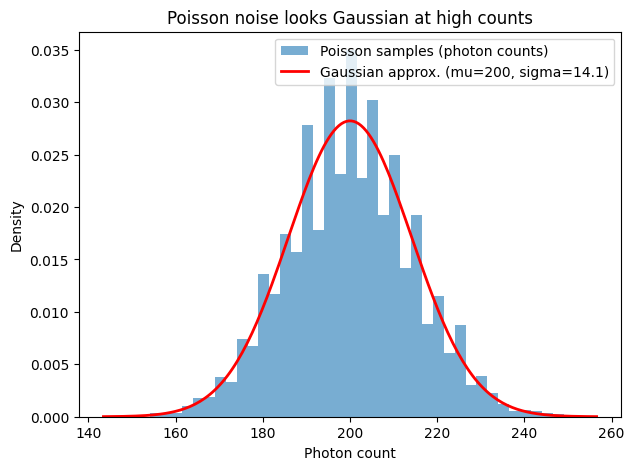

In [26]:
# 1D: Poisson vs. its Gaussian approximation at high counts
lam = 200  # mean photon count
counts = np.random.poisson(lam, 5000)

x = np.linspace(lam - 4*np.sqrt(lam), lam + 4*np.sqrt(lam), 200)
gaussian_approx = norm.pdf(x, lam, np.sqrt(lam))

fig, ax = plt.subplots(figsize=(7, 5))
ax.hist(counts, bins=40, density=True, alpha=0.6, label='Poisson samples (photon counts)')
ax.plot(x, gaussian_approx, 'r-', lw=2, label=f'Gaussian approx. (mu={lam}, sigma={np.sqrt(lam):.1f})')
ax.set_xlabel('Photon count'); ax.set_ylabel('Density')
ax.set_title('Poisson noise looks Gaussian at high counts')
ax.legend()
plt.show()


**🔧 Try it yourself:** Change `lam = 200` to `lam = 5` (a very faint source, few photons expected) and re-run. Look closely at the histogram shape: it should now look noticeably lopsided (**skewed**), with a hard wall at zero (you can't detect a negative number of photons) — the Gaussian curve no longer fits well. This is exactly why faint-source photometry needs Poisson statistics rather than a Gaussian approximation, while bright-source photometry can usually get away with the simpler Gaussian assumption.



### What the next two code cells will do
Now we visualize a **joint** Gaussian distribution over two variables $x$ and $y$ as a 3D surface — the higher the surface, the more probable that combination of $(x, y)$ is. First a static view with a fixed correlation $\rho$ (rho), then an animation sweeping $\rho$ from strongly negative to strongly positive so you can watch the "hill" tilt and stretch.


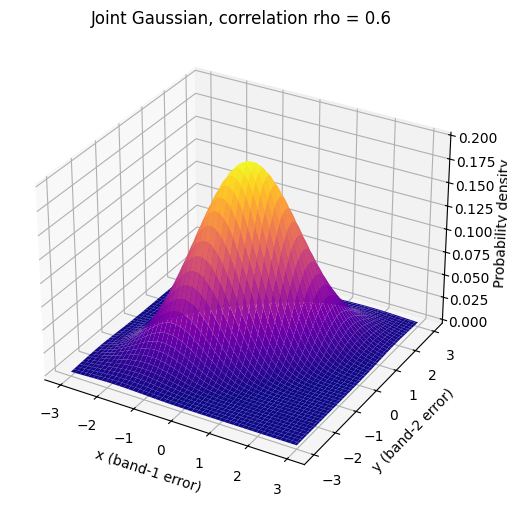

In [27]:

# 3D: a joint (bivariate) Gaussian, e.g. correlated errors between two bands
x_grid = np.linspace(-3, 3, 100)
y_grid = np.linspace(-3, 3, 100)
X, Y = np.meshgrid(x_grid, y_grid)
pos = np.dstack((X, Y))

rho = 0.6
cov_2d = [[1, rho], [rho, 1]]
Z = multivariate_normal([0, 0], cov_2d).pdf(pos)

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(X, Y, Z, cmap='plasma')
ax.set_xlabel('x (band-1 error)'); ax.set_ylabel('y (band-2 error)')
ax.set_zlabel('Probability density')
ax.set_title(f'Joint Gaussian, correlation rho = {rho}')
plt.show()


In [ ]:

# Animated: watch the joint distribution reshape as correlation rho changes
fig = plt.figure(figsize=(7, 6))
ax = fig.add_subplot(111, projection='3d')
rhos = np.linspace(-0.9, 0.9, 25)

def update(i):
    ax.clear()
    rho_i = rhos[i]
    cov_i = [[1, rho_i], [rho_i, 1]]
    Z_i = multivariate_normal([0, 0], cov_i).pdf(pos)
    ax.plot_surface(X, Y, Z_i, cmap='plasma')
    ax.set_zlim(0, 0.3)
    ax.set_xlabel('x'); ax.set_ylabel('y'); ax.set_zlabel('density')
    ax.set_title(f'Joint Gaussian, rho = {rho_i:.2f}')
    return ()

anim = FuncAnimation(fig, update, frames=len(rhos), interval=150)
plt.close(fig)
HTML(anim.to_jshtml())


**🔧 Try it yourself:** In the static plot cell, set `rho = 0` and re-run — the hill should now be perfectly circular (symmetric), meaning $x$ and $y$ tell you nothing about each other. Then try `rho = 0.99` — the hill should collapse into a thin diagonal ridge, meaning if you know $x$ you can almost perfectly predict $y$. In the animation, pause around `rho ≈ 0` and notice this is exactly the moment the "tilt" flips from a negative-diagonal ridge to a positive-diagonal one.



## 6. Bayes' Theorem — Updating Belief as Data Arrives

### The idea, in plain language
Imagine you're trying to estimate the outside temperature using a slightly unreliable thermometer that gives a noisy reading each time you check it. Before looking at all, you probably have some rough guess ("it's probably around 20°C, since it's usually mild this time of year") — that's your **prior**. Each time you check the thermometer, you get new evidence. Bayes' theorem tells you exactly how to mathematically combine your prior guess with each new noisy reading to get an updated, better-informed guess — the **posterior**:
$$P(\theta \mid D) = \frac{P(D \mid \theta)\, P(\theta)}{P(D)} \ \propto\ \underbrace{P(D \mid \theta)}_{\text{likelihood}}\ \underbrace{P(\theta)}_{\text{prior}}$$

In words: your updated belief about a parameter $\theta$, after seeing data $D$, is proportional to (how likely that data would be if $\theta$ were true) times (how much you believed in $\theta$ before seeing any data).

### Why this matters for astronomy and for ML
Almost every physical parameter you'll ever estimate — a star's temperature, a galaxy's redshift, a cosmological parameter — is estimated from noisy data, often combined with prior physical knowledge (e.g., "effective temperatures below 2000 K or above 50000 K are essentially impossible for main-sequence stars"). Bayesian reasoning gives you a principled way to combine that physical knowledge with your measurements, and to track exactly how *confident* you should be (not just a single best-guess number, but a full distribution of plausible values).

### The example we'll work through
We'll simulate 12 noisy temperature measurements of a star with a true effective temperature of 5800 K, starting from a slightly-off prior belief (mean 6000 K), and update our belief one measurement at a time. Watch how the posterior distribution both **shifts toward the true value** and **gets narrower** (more confident) as evidence accumulates.


In [28]:
# Bayesian updating: estimating a star's effective temperature from noisy measurements
true_value = 5800  # K (ground truth, unknown to our "instrument")
np.random.seed(1)
measurements = true_value + np.random.normal(0, 150, 12)  # 12 noisy measurements

theta = np.linspace(4500, 7000, 300)
prior_mean, prior_var = 6000, 400**2
obs_var = 150**2

# Precompute the sequence of posteriors (conjugate Gaussian-Gaussian update)
means, variances = [prior_mean], [prior_var]
mean, var = prior_mean, prior_var
for m in measurements:
    mean = (mean*obs_var + m*var) / (var + obs_var)
    var = (var*obs_var) / (var + obs_var)
    means.append(mean)
    variances.append(var)

print("Prior belief: mean =", prior_mean, "K, std =", int(np.sqrt(prior_var)), "K")
print("Posterior after all data: mean =", round(means[-1]), "K, std =", round(np.sqrt(variances[-1])), "K")
print("True value:", true_value, "K")

Prior belief: mean = 6000 K, std = 400 K
Posterior after all data: mean = 5783 K, std = 43 K
True value: 5800 K



### What the animation below will show
A single evolving curve: the posterior distribution over temperature, redrawn after each new measurement is incorporated. Watch both its **position** (does it drift toward 5800 K, the true value?) and its **width** (does it get narrower, meaning more confident, as more data comes in?).


In [29]:

# Animated: watch the posterior sharpen as each new observation arrives
fig, ax = plt.subplots(figsize=(7, 5))
line, = ax.plot([], [], lw=2, color='C0')
ax.axvline(true_value, color='k', linestyle=':', label='true value')
ax.set_xlim(4500, 7000)
ax.set_ylim(0, 0.006)
ax.set_xlabel('Effective temperature (K)')
ax.set_ylabel('Posterior density')
ax.legend(loc='upper left')
title = ax.set_title('')

def init():
    line.set_data([], [])
    return line, title

def update(i):
    posterior = norm.pdf(theta, means[i], np.sqrt(variances[i]))
    line.set_data(theta, posterior)
    title.set_text(f'Posterior after {i} observation(s)')
    return line, title

anim = FuncAnimation(fig, update, frames=len(means), init_func=init, interval=500)
plt.close(fig)
HTML(anim.to_jshtml())


**🔧 Try it yourself:**
- Set `prior_var = 50**2` (a much more *confident*, but wrong, prior) and re-run both cells. Notice it now takes visibly more observations to pull the posterior over to the true value — a strong prior takes more evidence to overturn.
- Set `prior_var = 2000**2` (a nearly clueless prior) and re-run — the posterior should snap almost immediately to what the data says, since you started with almost no fixed opinion.
- Add more simulated measurements (change `12` to `50` in `np.random.normal(0, 150, 12)`) and watch the final posterior become even narrower — more data always means more confidence (assuming your model of the noise is correct).



## 7. Maximum Likelihood Estimation (MLE)

### The idea, in plain language
MLE asks a more direct question than the Bayesian approach: forget about prior beliefs — **which parameter values make the data I actually observed as probable as possible?** Formally:
$$\hat\theta_{MLE} = \arg\max_\theta \ \sum_i \log P(x_i \mid \theta)$$

(We work with the *log* of the probability rather than the raw probability purely for numerical convenience — logs turn products into sums, which is much easier for a computer to handle accurately, and the location of the maximum is unaffected by this change.)

### The connection back to Section 3 (this is worth pausing on)
Finding the MLE means *searching a likelihood surface for its highest point* — mathematically the exact same kind of problem as gradient descent searching a loss surface for its lowest point, just flipped in sign (climbing up instead of walking down). In fact, for data with Gaussian noise, maximizing the likelihood turns out to be mathematically identical to minimizing the mean squared error from Section 3. This is not a coincidence you need to memorize — it's worth understanding: **least-squares fitting, which you may have already used, is secretly doing maximum likelihood estimation under a Gaussian noise assumption.**

### What the code below will do
We'll simulate 200 noisy magnitude measurements around a true value, then compute the log-likelihood for a grid of possible $(\mu, \sigma)$ values and plot it as a 3D surface, marking the peak — the MLE estimate. We'll compare it against the simple sample mean and standard deviation, which you'll see match almost exactly (for a Gaussian, they're mathematically the same thing).


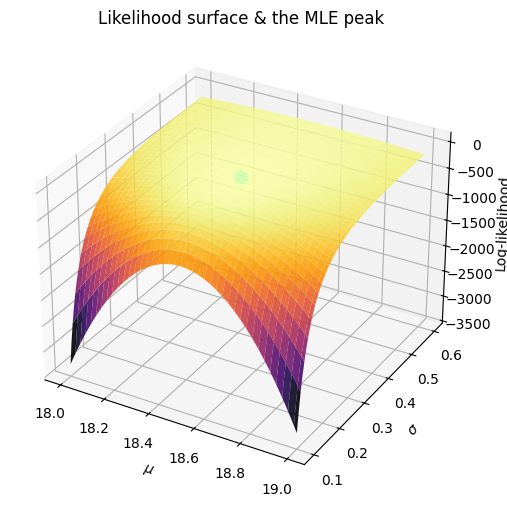

MLE estimate: mu = 18.506, sigma = 0.322
Sample mean/std (should match closely): mu = 18.504, sigma = 0.324


In [ ]:
# Fit a Gaussian (mu, sigma) to noisy magnitude measurements by maximum likelihood
np.random.seed(2)
mags = np.random.normal(18.5, 0.3, 200)

def log_likelihood(mu, sigma):
    return np.sum(-0.5*np.log(2*np.pi*sigma**2) - (mags - mu)**2 / (2*sigma**2))

mu_range = np.linspace(18.0, 19.0, 80)
sigma_range = np.linspace(0.1, 0.6, 80)
MU, SIGMA = np.meshgrid(mu_range, sigma_range)
LL = np.vectorize(log_likelihood)(MU, SIGMA)

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(MU, SIGMA, LL, cmap='inferno', alpha=0.9)
best = np.unravel_index(np.argmax(LL), LL.shape)
ax.scatter(MU[best], SIGMA[best], LL[best], color='cyan', s=80, label='MLE peak')
ax.set_xlabel(r'$\mu$'); ax.set_ylabel(r'$\sigma$'); ax.set_zlabel('Log-likelihood')
ax.set_title('Likelihood surface & the MLE peak')
plt.show()

print(f"MLE estimate: mu = {MU[best]:.3f}, sigma = {SIGMA[best]:.3f}")
print(f"Sample mean/std (should match closely): mu = {mags.mean():.3f}, sigma = {mags.std():.3f}")


**🔧 Try it yourself:** Change `200` (in `np.random.normal(18.5, 0.3, 200)`) to `10` and re-run. Look at the shape of the peak in the 3D plot — with only 10 data points it should be visibly *broader and flatter*, meaning many different $(\mu, \sigma)$ combinations are almost equally plausible. This directly echoes what you saw in Section 6: **less data means less certainty**, whether you think about it through likelihood surfaces or through Bayesian posteriors — they're two views of the same underlying idea.



## 8. Bias–Variance Tradeoff

### The idea, in plain language
Suppose you're fitting a curve to noisy data. If your model is too simple (e.g., a straight line trying to fit a wavy pattern), it can't capture the real shape no matter how much data you give it — this is **underfitting**, also called **high bias**: the model's assumptions are too restrictive. If your model is too complex (e.g., a wiggly high-degree polynomial with enough flexibility to pass through every single noisy data point), it starts fitting the *noise itself*, not just the underlying pattern — this is **overfitting**, also called **high variance**: small changes in the training data would produce wildly different fitted curves.

The tradeoff matters constantly in this course: every model you build (linear regression, random forests, neural networks) has "knobs" that control its complexity, and finding the right setting — not too simple, not too flexible — is one of the central practical skills in machine learning.

### What the code below will do
We'll fit three polynomials of different degrees (1, 4, and 15) to the same noisy dataset, and plot all three against the true underlying signal, so you can see underfitting and overfitting side by side rather than just as abstract terms.


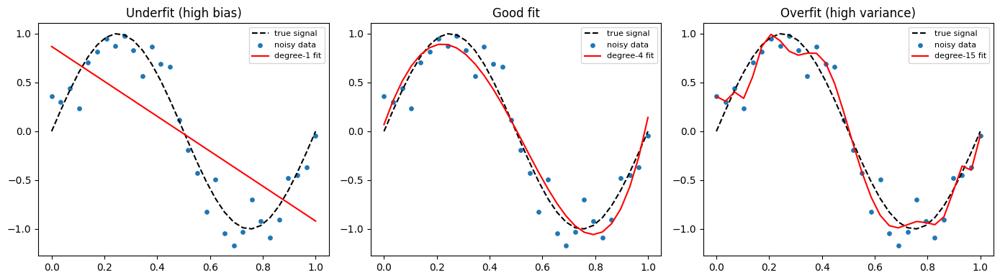

In [ ]:
np.random.seed(3)
x = np.linspace(0, 1, 30)
y_true = np.sin(2*np.pi*x)
y = y_true + np.random.normal(0, 0.2, len(x))

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, deg, title in zip(axes, [1, 4, 15],
                           ['Underfit (high bias)', 'Good fit', 'Overfit (high variance)']):
    coeffs = np.polyfit(x, y, deg)
    y_fit = np.polyval(coeffs, x)
    ax.plot(x, y_true, 'k--', label='true signal')
    ax.scatter(x, y, s=15, label='noisy data')
    ax.plot(x, y_fit, 'r', label=f'degree-{deg} fit')
    ax.set_title(title); ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


**🔧 Try it yourself:** Change the noise level `np.random.normal(0, 0.2, len(x))` to `0, 0.5` (noisier data) and re-run — watch the degree-15 fit get *even more* erratic, chasing the extra noise. Then reduce the number of data points from `30` to `10` and re-run with the original noise level — notice overfitting gets visibly worse with less data (there's more "room" for a flexible curve to memorize a small dataset than a large one). This is exactly why more training data generally reduces overfitting risk in real ML models.



## 9. Self-Check Questions

Before Session 1, make sure you can answer these in your own words (no need to submit — they're for your own confidence check):

1. If $\nabla f(\theta) = (2, -3)$ at a point, which direction should gradient *descent* step, and why?
2. Why does a smaller learning rate $\eta$ make gradient descent slower but safer, and what does "unsafe" (too large $\eta$) actually look like in a plot?
3. In the eigenvector plot (Section 4), what does it mean if one eigenvalue is much larger than the other two?
4. Why does a Poisson distribution start to look Gaussian at high counts, but not at low counts?
5. In the Bayesian updating animation, what would happen to the posterior if the prior had a much smaller variance (a stronger initial belief)? What if the prior had a much larger variance?
6. What's the practical difference between the MLE approach (Section 7) and the Bayesian approach (Section 6)? When might you prefer one over the other?
7. Looking at the three fits in Section 8, which one would generalize best to *new*, unseen data, and why — and what would happen to each fit if you doubled the amount of training data?

You're ready for Session 1 once you can answer all seven without looking back at the notebook — ideally by explaining them out loud to a labmate, since teaching a concept is the fastest way to find the gaps in your own understanding.
